# Which industries performed best?

This notebook asks: **Which industry groups performed best using our chosen pairs-trading strategy?**

It examines saved results from notebook 4. It does not run new trades or change the trading rules.

**The code cell below** finds the strategy with the highest Sharpe from notebook 4. It loads the trades, account values, and industry labels. Sharpe measures return relative to risk; higher is better.

These results use the same historical data used to choose the strategy, and exclude trading costs. They help us find candidates for further testing, rather than prove which industries will work in the future.


In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from risk_free import annualized_treasury_return, load_treasury_yields

# Set RUN_ID explicitly if multiple saved searches exist; never choose by modification time.
RUN_ID = None
base = ROOT / 'outputs' / 'joint_grid_search_zero_cost'
runs = sorted(p.parent for p in base.glob('*/grid_summary.csv'))
if RUN_ID is None:
    if len(runs) != 1:
        raise ValueError(f'Set RUN_ID to one of {[p.name for p in runs]}')
    run = runs[0]
else:
    run = base / RUN_ID
summary = pd.read_csv(run / 'grid_summary.csv')
complete = summary.loc[summary['Status'].eq('complete') & np.isfinite(summary['Sharpe Ratio'])]
if complete.empty:
    raise ValueError('No completed strategy with a finite Sharpe ratio')
winner = complete.sort_values('Sharpe Ratio', ascending=False, kind='stable').iloc[0]
folder = run / Path(winner['Output Folder']).name
params = json.loads((folder / 'parameters.json').read_text())
assert params['cost_bps_per_leg'] == 0
initial = params['initial_capital']
print(f'Run: {run.name}; complete: {summary.Status.eq("complete").sum()} / {len(summary)}')
print(json.dumps(params, indent=2))
display(winner.to_frame('Best saved strategy'))

portfolio = pd.read_csv(folder / 'portfolio_daily.csv', parse_dates=['Date']).set_index('Date').sort_index()
windows = pd.read_csv(folder / 'window_summary.csv')
selected = pd.read_csv(folder / 'selected_pairs.csv', dtype={'Industry Group Code': str})
trades = pd.read_csv(folder / 'trades.csv', parse_dates=['Entry Date', 'Exit Date'])
daily = pd.read_csv(folder / 'pair_daily.csv.gz', parse_dates=['Date'])
mapping = pd.read_csv(ROOT / 'data/gics/ticker_gics.csv', dtype=str)
assert portfolio.index.is_unique and portfolio.index.max() < pd.Timestamp('2023-08-25')
assert not selected.duplicated(['Window', 'A', 'B']).any()
keys = ['Window', 'A', 'B']
labels = selected[keys + ['Industry Group Code', 'Industry Group']]
daily = daily.merge(labels, on=keys, how='left', validate='many_to_one')
trades = trades.merge(labels, on=keys, how='left', validate='many_to_one')
assert daily['Industry Group Code'].notna().all() and trades['Industry Group Code'].notna().all()
assert selected['Industry Group Code'].str.fullmatch(r'\d{4}').all()
sector_labels = mapping[['Industry Group Code', 'Sector Code', 'Sector']].drop_duplicates()
assert not sector_labels['Industry Group Code'].duplicated().any()
all_groups = sector_labels.merge(mapping[['Industry Group Code', 'Industry Group']].drop_duplicates(),
                                on='Industry Group Code', validate='one_to_one')
treasury_path = ROOT / 'data/risk_free/DGS3MO.csv'
assert treasury_path.exists(), 'Local Treasury snapshot required'
yields = load_treasury_yields(treasury_path)
rf = annualized_treasury_return(portfolio.index, yields)


Run: cb64c19613e1e11beb71; complete: 1248 / 1248
{
  "formation_months": 18,
  "trading_months": 6,
  "correlation_threshold": 0.8,
  "eg_significance": 0.01,
  "entry_z": 1.5,
  "exit_z": 0.5,
  "stop_z": 4.0,
  "run_id": "cb64c19613e1e11beb71",
  "cost_bps_per_leg": 0.0,
  "initial_capital": 100000.0
}


,Best saved strategy
formation_months,18
trading_months,6
correlation_threshold,0.8
eg_significance,0.01
entry_z,1.5
exit_z,0.5
stop_z,4.0
Cumulative Return,0.186084
Gross Cumulative Return,0.186084
Annualized Return,0.024193


## Build a report card for each industry

We compare industries in two ways:

- **Actual profit:** How many dollars did this industry earn for our portfolio? This depends partly on how much money it received.
- **Industry sleeve:** How would an account containing only this industry's selected pairs have performed? This helps compare industries despite their different allocations. When no pairs are available, this account holds cash earning no interest.

Our actual portfolio divides money equally among selected pairs at the start of each trading window. An industry with more selected pairs therefore receives more money.

**The code cell below** calculates each industry's profit, return, Sharpe, biggest decline, win rate, and trade count. It also checks that all industry profits add up to the portfolio's profit.

Useful table terms:

- **PnL:** Profit or loss in dollars.
- **Contribution (pp):** The industry's contribution to total portfolio return, in percentage points.
- **CAGR:** The compounded annual growth rate.
- **Volatility:** How much daily returns fluctuate.
- **Max drawdown:** The biggest fall from a previous account peak.
- **Win rate:** The percentage of trades that made money.
- **Coverage screen:** At least 20 trades, 5 trading windows with trades, and 3 different pairs. This flags limited trading history; it does not prove reliability.


In [2]:
window_capital = windows.set_index('Window')['Initial Capital']
counts = selected.groupby('Window').size()
daily['Initial Allocation'] = daily['Window'].map(window_capital / counts)
daily = daily.sort_values(keys + ['Date'])
previous_pair = daily.groupby(keys)['Equity'].shift()
previous_pair = previous_pair.fillna(daily['Initial Allocation'])
daily['Daily PnL'] = daily['Equity'] - previous_pair
agg = daily.groupby(['Date', 'Industry Group Code']).agg(
    equity=('Equity', 'sum'), pnl=('Daily PnL', 'sum'),
    active=('Position', lambda x: x.ne(0).sum()))
agg['prior'] = agg.equity - agg.pnl
agg['return'] = agg.pnl / agg.prior
codes = sorted(all_groups['Industry Group Code'])
returns = agg['return'].unstack().reindex(index=portfolio.index, columns=codes).fillna(0)
pnl = agg['pnl'].unstack().reindex(index=portfolio.index, columns=codes).fillna(0)
active = agg['active'].unstack().reindex(index=portfolio.index, columns=codes).fillna(0)
nav = (1 + returns).cumprod()
portfolio_pnl = portfolio.Equity.diff().fillna(portfolio.Equity.iloc[0] - initial)
np.testing.assert_allclose(pnl.sum(axis=1), portfolio_pnl, atol=1e-7)
np.testing.assert_allclose(pnl.to_numpy().sum(), trades['Net P/L ($)'].sum(), atol=1e-6)
np.testing.assert_allclose(pnl.to_numpy().sum(), portfolio.Equity.iloc[-1] - initial, atol=1e-6)
print('Daily, trade, and final-equity P&L reconciliations passed.')

rows = []
for group in all_groups.to_dict('records'):
    g = group['Industry Group Code']; r = returns[g]; v = nav[g]
    t = trades.loc[trades['Industry Group Code'].eq(g)]
    s = selected.loc[selected['Industry Group Code'].eq(g)]
    wr = (1 + r).groupby(portfolio.Window).prod() - 1
    present = sorted(s.Window.unique())
    annual = v.iloc[-1] ** (252 / len(v)) - 1
    vol = r.std(ddof=1) * np.sqrt(252)
    profit = t.loc[t['Net P/L ($)'].gt(0), 'Net P/L ($)'].sum()
    loss = -t.loc[t['Net P/L ($)'].lt(0), 'Net P/L ($)'].sum()
    pairs = {tuple(sorted((a,b))) for a,b in zip(s.A,s.B)}
    rows.append(group | {
        'Selected pair-windows': len(s), 'Unique pairs': len(pairs),
        'Selected windows': len(present), 'Traded windows': t.Window.nunique(),
        'Active days (%)': active[g].gt(0).mean() * 100, 'Trades': len(t),
        'PnL ($)': pnl[g].sum(), 'Contribution (pp)': pnl[g].sum() / initial * 100,
        'Sleeve total return': v.iloc[-1] - 1, 'CAGR': annual,
        'Volatility': vol, 'Sharpe': (annual-rf)/vol if vol > 1e-12 else np.nan,
        'Max drawdown': -(v / v.cummax().clip(lower=1) - 1).min(),
        'Win rate': t['Net P/L ($)'].gt(0).mean(),
        'Profit factor': profit/loss if loss > 0 else (np.inf if profit > 0 else np.nan),
        'Mean-reversion exit rate': t['Exit Reason'].eq('Mean reversion').mean(),
        'Stop exit rate': t['Exit Reason'].eq('Stop loss').mean(),
        'Window-end exit rate': t['Exit Reason'].eq('End of window').mean(),
        'Median holding sessions': t['Holding Sessions'].median(),
        'Mean trade return': t['Net Return'].mean(),
        'Profitable selected windows': wr.reindex(present).gt(0).mean() if present else np.nan,
    })
ranking = pd.DataFrame(rows).sort_values('Sharpe', ascending=False, na_position='last')
# A transparent coverage screen, not a statistical significance test.
ranking['Coverage screen'] = (ranking.Trades >= 20) & (ranking['Traded windows'] >= 5) & (ranking['Unique pairs'] >= 3)
pd.set_option('display.max_columns', 35)
display(ranking.round(4))


Daily, trade, and final-equity P&L reconciliations passed.


,Industry Group Code,Sector Code,Sector,Industry Group,Selected pair-windows,Unique pairs,Selected windows,Traded windows,Active days (%),Trades,PnL ($),Contribution (pp),Sleeve total return,CAGR,Volatility,Sharpe,Max drawdown,Win rate,Profit factor,Mean-reversion exit rate,Stop exit rate,Window-end exit rate,Median holding sessions,Mean trade return,Profitable selected windows,Coverage screen
2,2530,25,Consumer Discretionary,Consumer Services,3,3,3,3,13.5075,8,1919.2966,1.9193,0.2129,0.0274,0.0407,0.2984,0.0503,0.8750,65.6569,0.7500,0.0000,0.2500,18.0,0.0245,1.0000,False
12,4020,40,Financials,Financial Services,10,10,4,4,11.6176,16,5147.6528,5.1477,0.1693,0.0222,0.0256,0.2687,0.0441,0.7500,7.6476,0.6875,0.2500,0.0625,15.5,0.0162,0.7500,False
10,1510,15,Materials,Materials,2,1,2,2,7.3930,8,2120.1152,2.1201,0.1266,0.0168,0.0293,0.0536,0.0365,0.8750,4.1300,0.7500,0.1250,0.1250,18.5,0.0153,0.5000,False
18,4010,40,Financials,Banks,25,21,11,11,39.6887,48,545.8045,0.5458,0.1170,0.0156,0.0331,0.0106,0.0543,0.5625,1.1023,0.5625,0.2500,0.1875,19.5,0.0007,0.5455,True
15,1010,10,Energy,Energy,6,4,4,3,13.9522,6,1159.5993,1.1596,0.0607,0.0083,0.0676,-0.1032,0.1291,0.8333,1.8869,0.5000,0.1667,0.3333,55.0,0.0326,0.5000,False
6,4530,45,Information Technology,Semiconductors & Semiconductor Equipment,4,4,3,3,8.5047,5,1353.7614,1.3538,0.0608,0.0083,0.0248,-0.2805,0.0823,0.6000,3.1415,0.4000,0.4000,0.2000,27.0,0.0015,0.6667,False
9,5510,55,Utilities,Utilities,56,43,14,14,60.1445,80,769.3349,0.7693,0.0640,0.0087,0.0202,-0.3242,0.0370,0.5625,1.1154,0.5125,0.3250,0.1625,18.0,0.0015,0.3571,True
23,2520,25,Consumer Discretionary,Consumer Durables & Apparel,3,3,3,3,6.2257,5,219.5862,0.2196,-0.0026,-0.0004,0.0400,-0.3904,0.0919,0.6000,1.1739,0.4000,0.4000,0.2000,22.0,0.0002,0.6667,False
22,2030,20,Industrials,Transportation,6,5,4,4,15.8421,9,2800.4091,2.8004,0.0026,0.0004,0.0365,-0.4086,0.0866,0.6667,1.7425,0.4444,0.3333,0.2222,14.0,0.0047,0.5000,False
4,4030,40,Financials,Insurance,1,1,1,1,4.9472,3,1202.1678,1.2022,0.0623,0.0085,0.0141,-0.4782,0.0253,1.0000,inf,0.6667,0.0000,0.3333,37.0,0.0204,1.0000,False


## Read the charts

**The code cell below** draws these charts:

- **Left bar chart — industry sleeve Sharpe:** Which industries earned better returns for the risk taken? Higher is better.
- **Right bar chart — actual contribution:** How much did each industry add to our portfolio's return? Negative bars mean it lost money.
- **Line chart — growth of $1:** How would $1 have grown in each industry sleeve? The black line shows our actual combined portfolio. A value of $1.20 means a 20% total gain.
- **Colour grid — returns by trading window:** Each row is an industry; each column is a trading period. Use the colour bar to identify gains and losses. Blank means no pairs were selected for that industry in that period.

Look for results that hold up across several periods. A high win rate alone is insufficient: a few large losses can erase many small wins.


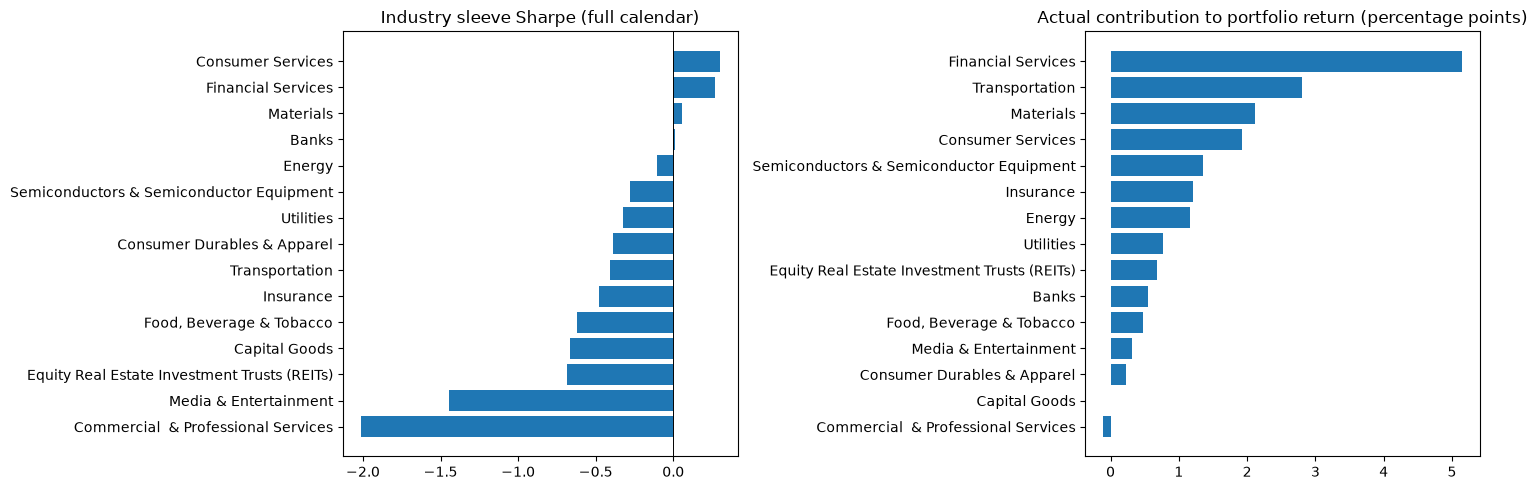

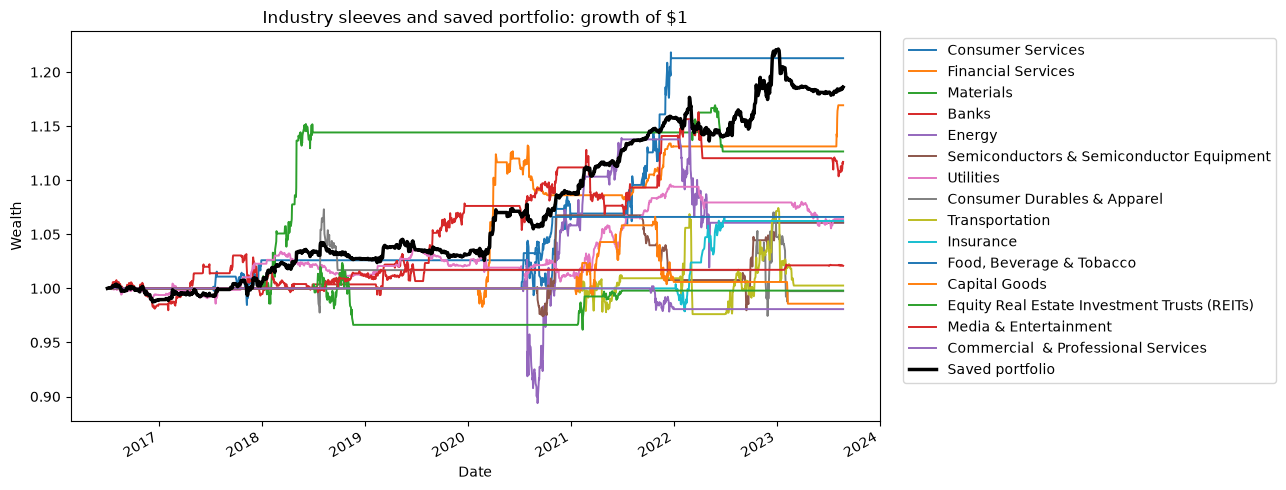

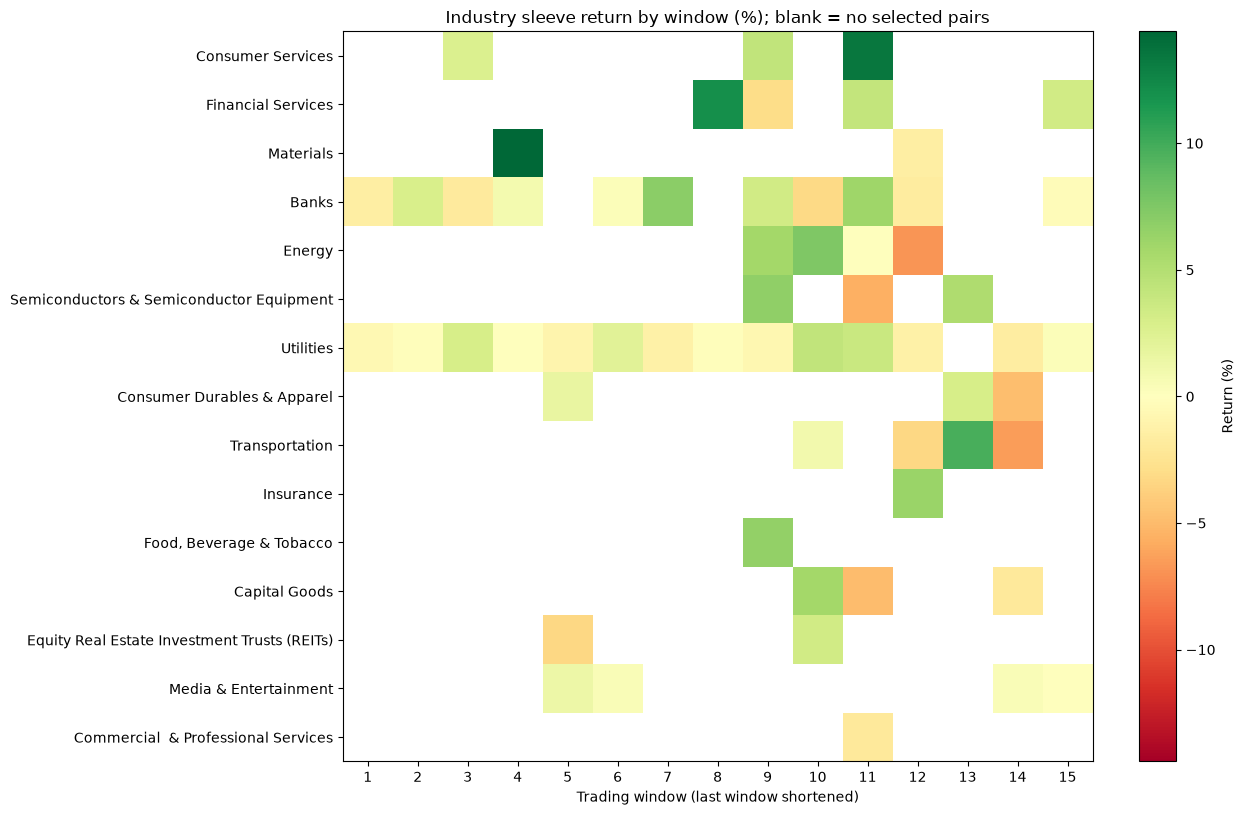

Industry Group Code,Consumer Services,Financial Services,Materials,Banks,Energy,Semiconductors & Semiconductor Equipment,Utilities,Consumer Durables & Apparel,Transportation,Insurance,"Food, Beverage & Tobacco",Capital Goods,Equity Real Estate Investment Trusts (REITs),Media & Entertainment,Commercial & Professional Services
Window,,,,,,,,,,,,,,,
1,0.0000,0.0000,0.0000,-0.0147,0.0000,0.0000,-0.0061,0.0000,0.0000,0.0000,0.000,0.0000,0.0000,0.0000,0.0000
2,0.0000,0.0000,0.0000,0.0292,0.0000,0.0000,-0.0012,0.0000,0.0000,0.0000,0.000,0.0000,0.0000,0.0000,0.0000
3,0.0260,0.0000,0.0000,-0.0190,0.0000,0.0000,0.0303,0.0000,0.0000,0.0000,0.000,0.0000,0.0000,0.0000,0.0000
4,0.0000,0.0000,0.1442,0.0090,0.0000,0.0000,-0.0005,0.0000,0.0000,0.0000,0.000,0.0000,0.0000,0.0000,0.0000
5,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,-0.0093,0.0169,0.0000,0.0000,0.000,0.0000,-0.0337,0.0127,0.0000
6,0.0000,0.0000,0.0000,0.0031,0.0000,0.0000,0.0220,0.0000,0.0000,0.0000,0.000,0.0000,0.0000,0.0044,0.0000
7,0.0000,0.0000,0.0000,0.0690,0.0000,0.0000,-0.0133,0.0000,0.0000,0.0000,0.000,0.0000,0.0000,0.0000,0.0000
8,0.0000,0.1201,0.0000,0.0000,0.0000,0.0000,-0.0021,0.0000,0.0000,0.0000,0.000,0.0000,0.0000,0.0000,0.0000
9,0.0421,-0.0303,0.0000,0.0331,0.0582,0.0676,-0.0074,0.0000,0.0000,0.0000,0.066,0.0000,0.0000,0.0000,0.0000


In [3]:
observed = ranking.loc[ranking['Selected pair-windows'].gt(0)]
names = observed.set_index('Industry Group Code')['Industry Group'].to_dict()
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
plot = observed.sort_values('Sharpe')
axes[0].barh(plot['Industry Group'], plot['Sharpe'])
axes[0].axvline(0, color='black', linewidth=.7)
axes[0].set_title('Industry sleeve Sharpe (full calendar)')
plot = observed.sort_values('Contribution (pp)')
axes[1].barh(plot['Industry Group'], plot['Contribution (pp)'])
axes[1].set_title('Actual contribution to portfolio return (percentage points)')
fig.tight_layout(); plt.show()

ax = nav[list(names)].rename(columns=names).plot(figsize=(13, 5), linewidth=1.4)
(portfolio.Equity / initial).plot(ax=ax, color='black', linewidth=2.5, label='Saved portfolio')
ax.set_title('Industry sleeves and saved portfolio: growth of $1'); ax.set_ylabel('Wealth')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left'); plt.tight_layout(); plt.show()

window_returns = (1 + returns).groupby(portfolio.Window).prod() - 1
selected_mask = pd.crosstab(selected.Window, selected['Industry Group Code']).reindex(
    index=window_returns.index, columns=list(names), fill_value=0).gt(0)
heat = window_returns[list(names)].where(selected_mask)
fig, ax = plt.subplots(figsize=(13, max(3, len(names)*.55)))
limit = max(np.nanmax(np.abs(heat.to_numpy())) * 100, .01)
im = ax.imshow(heat.T * 100, aspect='auto', cmap='RdYlGn', vmin=-limit, vmax=limit)
ax.set_yticks(range(len(names)), list(names.values()))
ax.set_xticks(range(len(heat)), heat.index)
ax.set_xlabel('Trading window (last window shortened)')
ax.set_title('Industry sleeve return by window (%); blank = no selected pairs')
fig.colorbar(im, ax=ax, label='Return (%)'); fig.tight_layout(); plt.show()
display(window_returns[list(names)].rename(columns=names).round(4))


## How did trades close in each sector?

Each pie chart groups **all completed trades** by two-digit GICS sector. Slices show the percentage closed at window end, by mean reversion, or by stop loss. Each chart title gives its total trade count; each slice gives its percentage and count.

Every trade counts once, regardless of profit or loss size. Sectors with no trades are labeled explicitly.


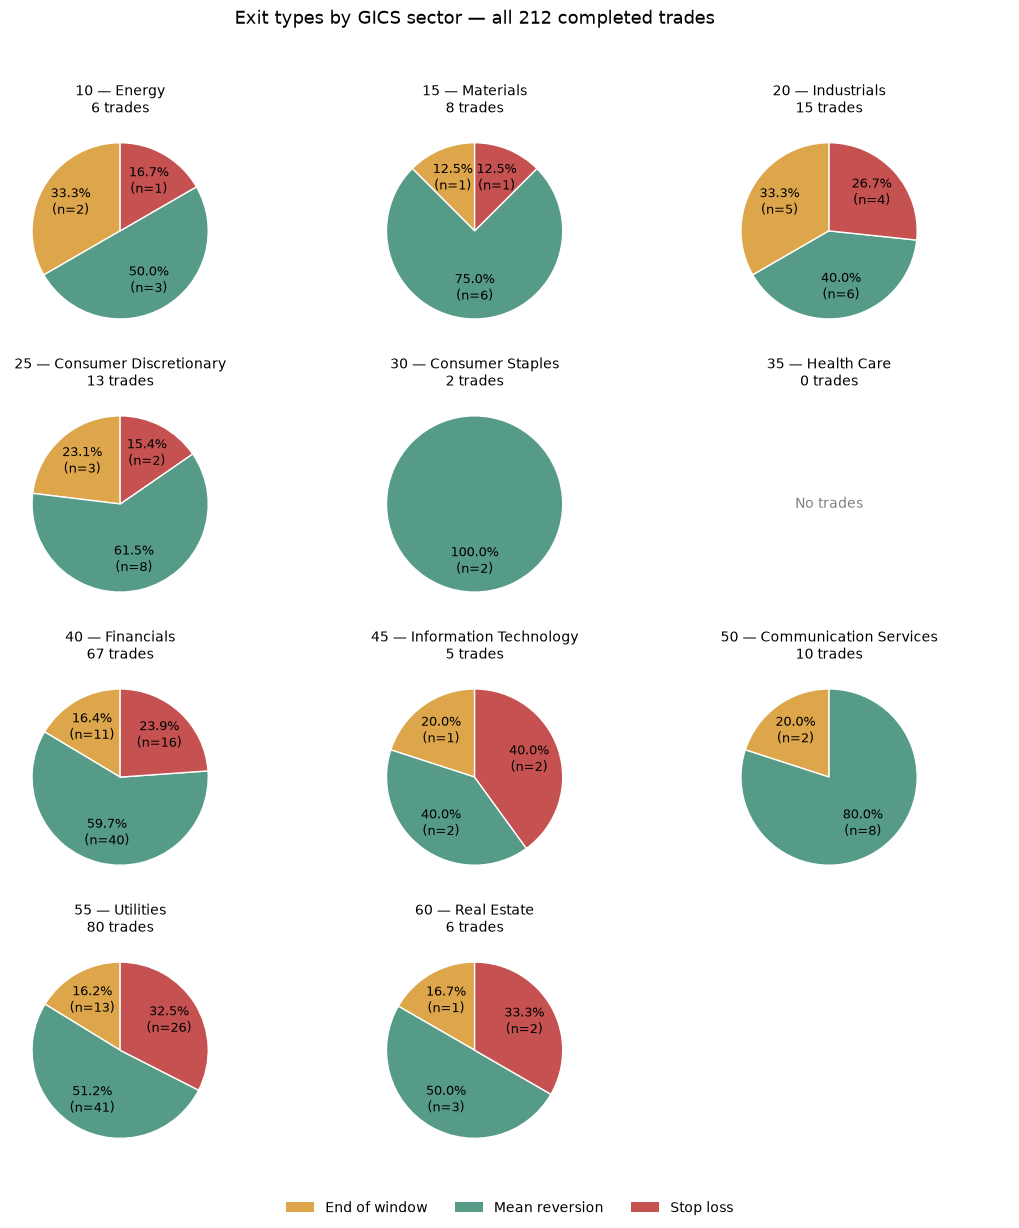

Saved sector chart and trade counts to outputs/industry_analysis_zero_cost/cb64c19613e1e11beb71/formation_months_18_trading_months_6_correlation_threshold_0.8_eg_significance_0.01_entry_z_1.5_exit_z_0.5_stop_z_4


In [4]:
# Exit types for all completed trades, grouped by two-digit GICS sector.
sector_map = mapping[['Ticker', 'Sector Code', 'Sector']].drop_duplicates()
assert not sector_map['Ticker'].duplicated().any()
sector_trades = trades.merge(
    sector_map.rename(columns={'Ticker': 'A'}), on='A', how='left', validate='many_to_one')
other_sector = trades['B'].map(sector_map.set_index('Ticker')['Sector Code'])
assert sector_trades['Sector Code'].notna().all()
assert sector_trades['Sector Code'].str.fullmatch(r'\d{2}').all()
assert (sector_trades['Sector Code'].to_numpy() == other_sector.to_numpy()).all(), 'Pair crosses sectors'
exit_order = ['End of window', 'Mean reversion', 'Stop loss']
exit_colors = ['#dda64b', '#559b87', '#c55151']
assert sector_trades['Exit Reason'].isin(exit_order).all()
sectors = sector_map[['Sector Code', 'Sector']].drop_duplicates().sort_values('Sector Code')
assert not sectors['Sector Code'].duplicated().any()
sector_exit_counts = pd.crosstab(sector_trades['Sector Code'], sector_trades['Exit Reason']).reindex(
    index=sectors['Sector Code'], columns=exit_order, fill_value=0)
assert int(sector_exit_counts.to_numpy().sum()) == len(trades)

ncols = 3
nrows = int(np.ceil(len(sectors) / ncols))
sector_fig, sector_axes = plt.subplots(nrows, ncols, figsize=(11, nrows * 3.1), squeeze=False)
for ax, (_, sector) in zip(sector_axes.flat, sectors.iterrows()):
    counts = sector_exit_counts.loc[sector['Sector Code']]
    total = int(counts.sum())
    ax.set_title(f"{sector['Sector Code']} — {sector['Sector']}\n{total} trades", fontsize=10)
    if total == 0:
        ax.text(.5, .5, 'No trades', ha='center', va='center', transform=ax.transAxes, color='gray')
        ax.set_axis_off()
        continue
    keep = counts.gt(0)
    values = counts.loc[keep].to_numpy()
    # Use the actual counts in labels, avoiding rounding percentage back to a count.
    labels = [f'{value / total:.1%}\n(n={value})' for value in values]
    ax.pie(values, labels=labels, labeldistance=.65,
           colors=[color for color, include in zip(exit_colors, keep) if include],
           startangle=90, textprops={'fontsize': 9, 'ha': 'center'},
           wedgeprops={'edgecolor': 'white', 'linewidth': 1})
for ax in list(sector_axes.flat)[len(sectors):]:
    ax.set_axis_off()
from matplotlib.patches import Patch
sector_fig.legend(handles=[Patch(facecolor=color, label=reason) for color, reason in zip(exit_colors, exit_order)],
                  loc='lower center', ncol=3, frameon=False)
sector_fig.suptitle(f'Exit types by GICS sector — all {len(trades)} completed trades', fontsize=13)
sector_fig.tight_layout(rect=(0, .04, 1, .96))
plt.show()

out = ROOT / 'outputs' / 'industry_analysis_zero_cost' / run.name / folder.name
out.mkdir(parents=True, exist_ok=True)
sector_fig.savefig(out / 'sector_exit_type_pies.png', dpi=160, bbox_inches='tight')
sector_exit_counts.to_csv(out / 'sector_exit_type_counts.csv')
print(f'Saved sector chart and trade counts to {out.relative_to(ROOT)}')
